# 02 — Exploratory analysis

**Question for this notebook:** what do the earthquake rate and the ground uplift look like over time, and how do they relate? This is looking before modelling. It does not measure forecasting skill: that comes in phase 7, with time-ordered splits.

**Plan:**
1. Event rate over time. *(this step)*
2. Uplift and uplift rate over time.
3. Uplift against cumulative event count (the paper's central relationship).
4. Event rate against uplift rate, including lags.
5. The M ≥ 3 events.
6. Map of events and GPS stations.

Throughout, "M ≥ 0.6" means events with Md (binned to 0.1) of at least `MC_MAIN` = 0.6, the magnitude of completeness chosen in `01_completeness`. Counts above Mc are comparable across years; counts of *all* events partly track the growth of the seismic network.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.completeness import MC_MAIN
from src.series import event_counts

events = pd.read_parquet("../data/processed/catalogue.parquet")
gps = pd.read_parquet("../data/processed/gps_daily.parquet")

# The last weeks of the catalogue are incomplete: the final bulletin lags a few weeks
# (see CLAUDE.md). Shade them on plots; leave them out of anything quantitative.
INCOMPLETE_FROM = pd.Timestamp("2026-09-01", tz="UTC")
print(f"Events: {events['time'].min():%Y-%m-%d} to {events['time'].max():%Y-%m-%d}")
print(f"GPS:    {gps['date'].min():%Y-%m-%d} to {gps['date'].max():%Y-%m-%d}")

Events: 2005-03-22 to 2026-10-21
GPS:    2000-01-01 to 2025-12-31


## 1. Event rate over time

Monthly event counts, for all events and for M ≥ 0.6, on a log scale. Months with no events can't be drawn on a log scale, so they show as gaps. (Weekly counts, which the targets will use, are summarised in the table below.)

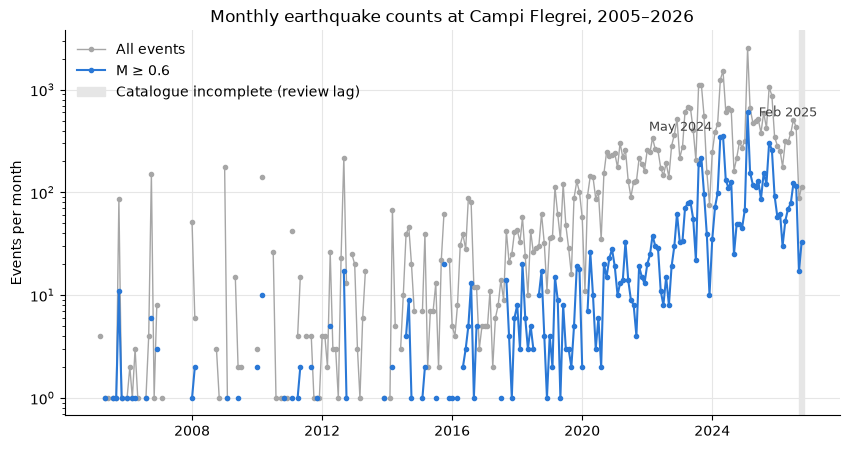

In [2]:
monthly_all = event_counts(events, "M", start="2005-01-01", end="2026-10-21")
monthly_mc = event_counts(events, "M", mc=MC_MAIN, start="2005-01-01", end="2026-10-21")
weekly_mc = event_counts(events, "W", mc=MC_MAIN, start="2005-01-03", end="2026-10-21")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(monthly_all.index, monthly_all.where(monthly_all > 0), marker="o", markersize=3,
        linewidth=1, color="0.65", label="All events")
ax.plot(monthly_mc.index, monthly_mc.where(monthly_mc > 0), marker="o", markersize=3,
        linewidth=1.5, color="#2a78d6", label=f"M ≥ {MC_MAIN}")
ax.axvspan(INCOMPLETE_FROM, monthly_all.index[-1] + pd.Timedelta(days=31), color="0.9",
           label="Catalogue incomplete (review lag)")

# Label two of the busiest swarms (placed by hand so the labels don't collide).
for month, offset in [("2025-02-01", (8, 0)), ("2024-05-01", (-8, 6))]:
    month = pd.Timestamp(month, tz="UTC")
    ax.annotate(f"{month:%b %Y}", (month, monthly_mc[month]), textcoords="offset points",
                xytext=offset, ha="left" if offset[0] > 0 else "right", va="center",
                fontsize=9, color="0.25")

ax.set_yscale("log")
ax.set_ylabel("Events per month")
ax.set_title("Monthly earthquake counts at Campi Flegrei, 2005–2026")
ax.grid(True, which="major", color="0.9", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.show()

How often is a week empty? This matters for the weekly-count target in phase 6: a series that is almost all zeros behaves very differently from one with tens of events a week.

In [3]:
complete = weekly_mc[weekly_mc.index < INCOMPLETE_FROM]
by_year = complete.groupby(complete.index.year).agg(
    weeks="size",
    events="sum",
    share_of_weeks_with_none=lambda s: (s == 0).mean(),
    median_per_week="median",
    max_per_week="max",
)
by_year.round(2)

,weeks,events,share_of_weeks_with_none,median_per_week,max_per_week
period_start,,,,,
2005,52,15,0.90,0.0,11
2006,52,13,0.88,0.0,6
2007,53,1,0.98,0.0,1
2008,52,2,0.96,0.0,1
2009,52,2,0.96,0.0,1
2010,52,13,0.94,0.0,10
2011,52,7,0.90,0.0,2
2012,53,23,0.91,0.0,13
2013,52,1,0.98,0.0,1


**What plot 1 shows:**

- **Two regimes.** Until about 2016, events with M ≥ 0.6 are rare: most months have none or one, with occasional short bursts (for example late 2005, 2012). From 2017–2018 the rate climbs steadily, from about 7 a month in 2018 to about 180 a month in 2025: roughly a doubling every 1.5 years, a straight-ish line on the log scale.
- **Swarms on top of the trend.** The busiest months are swarms around the larger earthquakes: May 2024 (the Md 4.4) and February 2025 (600 events at M ≥ 0.6 in one month).
- **2026 is quieter than 2025** (about 17 events a week at M ≥ 0.6 against 42), even before the incomplete last weeks (shaded).
- **For the weekly target (phase 6):** before 2018, 73–98% of weeks have no event at M ≥ 0.6; from 2023 almost every week has some, with a median of 10–27. A model has to handle both: a count model that allows many zeros (Poisson or negative binomial), and an evaluation that reports early and recent years separately. We may decide to train only from about 2018, where there is enough signal; that's a phase 6 decision.